# Practice Session PS05: Content-based recommendation

Author: <font color="#2680EB">Anna Quílez Rodríguez</font>

E-mail: <font color="#2680EB">anna.quilez01@estudiant.upf.edu</font>

AI used: <font color="#2680EB">ChatGPT. I used artificial intelligence to help me understand the functions I wasn’t familiar with and to write some of the code.</font>

Date: <font color="#2680EB">28/10/2026</font>

In [1]:
# LEAVE AS-IS

# Required libraries
import pandas as pd   
import numpy as np  
import re
import random

# Plotting libraries
import seaborn as sns
import matplotlib.pyplot as plt 

# Sci-kit specific libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
# LEAVE AS-IS

FILENAME_MOVIES = "movies.csv.gz"

In [3]:
# LEAVE AS-IS

# Load movies
movies = pd.read_csv(FILENAME_MOVIES, 
                    compression='gzip',
                    sep="\t", 
                    engine='python', 
                    encoding='utf-8')

# Display a random sample
print(f"Loaded {len(movies)} movies, here is a sample:")
display(movies.sample(3))

Loaded 9751 movies, here is a sample:


,id,title,overview,tags,genres,director,actors,characters,year,votes,rating,popularity,budget,poster_url
3062,9513,Garfield: A Tail of Two Kitties,"Jon and Garfield visit the United Kingdom, whe...",NaN,"animation,children,comedy",Tim Hill,"Rhys Ifans,Tim Curry,Billy Connolly,Bill Murra...","McBunny (voice),Prince (voice),Dargis,Garfield...",2006,1813,5.522,27.249,60000000,https://image.tmdb.org/t/p/w154/osfMaHucgLtHts...
51,1040603,Orgasm Inc: The Story of OneTaste,A sexual wellness company gains fame and follo...,NaN,Documentary,Sloane Klevin,NaN,NaN,2022,19,6.000,475.768,0,https://image.tmdb.org/t/p/w154/yqI3XQ1nmvxFpB...
8565,20726,Little Giants,When Danny O'Shea's daughter is cut from the P...,"kids movie,can't remember,american football coach","children,comedy",Duwayne Dunham,"Devon Sawa,Ed O'Neill,Frank Welker,Susanna Tho...","Junior Floyd,Kevin O'Shea,Animation Vocal Soun...",1994,359,6.375,12.682,0,https://image.tmdb.org/t/p/w154/AkfXNOeKgJSOD0...


# 1. Create a function to find movies <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement find_movies** to find movies containing a keyword.</font>

In [4]:
def find_movies(keyword, movies):
    # YOUR CODE HERE
    #I used AI to know the function .iterrorws() 
    for i, movie in movies.iterrows(): 
        if keyword.lower() in str(movie["title"]).lower():
            print(f"id: {movie['id']}, title: {movie['title']}")
find_movies("Purple", movies)

id: 762975, title: Purple Hearts
id: 873, title: The Color Purple


# 2. Distributions of genre and keywords

In [5]:
# LEAVE AS-IS

def print_genres(df):
    print(f"Movies         : {len(df)}" )
    print(f" Without genre : {df['genres'].isna().sum()}" )
    print(f" With genre    : {df['genres'].notna().sum()}" )
    print()

    
    all_genres = set()
    for s in df['genres'].dropna().str.split(',').values:
        all_genres = all_genres.union(set(s))
    print(all_genres)
    
print_genres(movies)
    

Movies         : 9751
 Without genre : 50
 With genre    : 9701

{'documentary', 'Thriller', 'adventure', 'War', 'romance', 'action', 'crime', 'sci-fi', 'western', 'animation', 'Documentary', 'imax', 'TV Movie', 'war', 'Music', 'Family', 'drama', 'Fantasy', 'thriller', 'mystery', 'horror', 'Mystery', 'Western', 'Romance', '(no genres listed)', 'Drama', 'History', 'Action', 'Crime', 'Horror', 'children', 'Science Fiction', 'fantasy', 'comedy', 'Adventure', 'Animation', 'Comedy', 'film-noir', 'musical'}


## 2.1. Prepare the "genre" column <font color="#2680EB">[15%]</font>

<font size="+1" color="#2680EB">**Indicate what problems do you see in the genre column, and how would you clean this column.**</font>

**Responses.**

What issues do you see in the list of genres below?

* Some genres have the same meaning but are written differently. For example, "Adventure" and "adventure" differ only in capitalization, while "Science Fiction" and "sci-fi" are different names for the same genre. There are also 50 movies without a genre, and the value "no genres listed" should be treated as a missing value rather than as a real genre.

How would you clean this column?

* I would convert all genre names to lowercase and replace alternative names with a single standard name to avoid duplicates. I would also replace "no genres listed" with a missing value (NULL). 


<font size="+1" color="#2680EB">**Clean the genre column**. In particular, make sure "(no genres listed)" is NULL, and that there are no (near)duplicate genres.</font>

In [6]:
movies1 = movies.copy()

# YOUR CODE HERE
# Convert genres to lowercase
movies1["genres"] = movies1["genres"].str.lower()

# Replace missing genre labels with NULL values
movies1["genres"] = movies1["genres"].replace("(no genres listed)", pd.NA)

# Standardize equivalent genre names
movies1["genres"] = movies1["genres"].str.replace("science fiction", "sci-fi", regex=False)

print_genres(movies1)

Movies         : 9751
 Without genre : 100
 With genre    : 9651

{'documentary', 'drama', 'thriller', 'adventure', 'romance', 'mystery', 'horror', 'music', 'family', 'action', 'crime', 'sci-fi', 'western', 'animation', 'tv movie', 'imax', 'war', 'history', 'children', 'fantasy', 'comedy', 'film-noir', 'musical'}


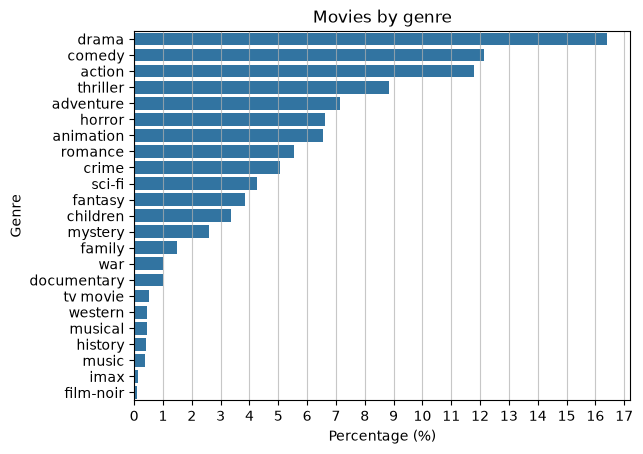

In [7]:
# LEAVE AS-IS

def plot_genres(df):
    
    # Convert genres into a list (i.e., "explode" it)
    exploded_genres = df['genres'].str.split(',').explode().str.strip()

    # Create frequency DataFrame
    genre_counts = exploded_genres.value_counts().reset_index()
    genre_counts.columns = ['genre', 'count']
    genre_counts['percent'] = (genre_counts['count'] / genre_counts['count'].sum()) * 100

    # Create barchart
    sns.barplot(data=genre_counts, x='percent', y='genre', legend=False)
    plt.title('Movies by genre')
    plt.xlabel('Percentage (%)')
    plt.ylabel('Genre')
    
    # Add vertical lines
    # The instructor used AI to set this grid (Gemini 3.6 Flash)
    max_percentage = int(np.ceil(genre_counts['percent'].max()))
    plt.xticks(np.arange(0, max_percentage + 1, 1 ))
    plt.grid(axis='x', alpha=0.7)
    
    plt.show()

plot_genres(movies1)

<font size="+1" color="#2680EB">**Merge genres** using the specification above.</font>

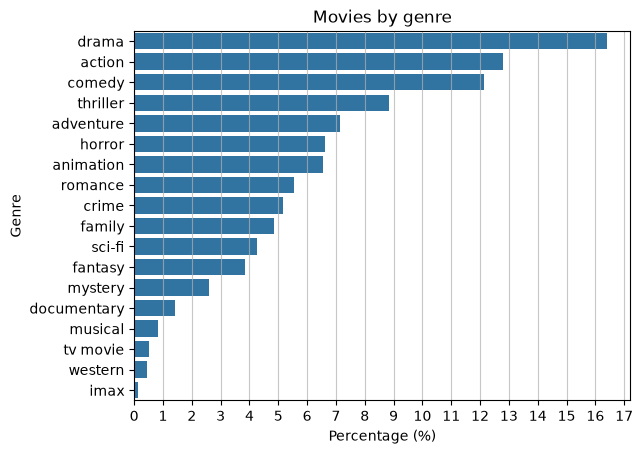

In [8]:
pairs_to_replace = [
    ('film-noir', 'crime'),
    ('music', 'musical'),
    ('science fiction', 'sci-fi'),
    ('history', 'documentary'),
    ('children', 'family'),
    ('war', 'action')
]

movies2 = movies1.copy()
# YOUR CODE HERE
# AI was used to understand how to replace complete genre names without creating incorrect labels.
for old, new in pairs_to_replace:
    movies2["genres"] = movies2["genres"].apply(
        lambda x: ",".join(
            new if genre.strip() == old else genre.strip()
            for genre in x.split(",")
        ) if pd.notna(x) else x
    )
plot_genres(movies2)

## 2.2. Merge genres and tags into keywords <font color="#2680EB">[15%]</font>

<font size="+1" color="#2680EB">**Create column "keywords".** It should contain a list, which should be the union of "genres" and "tags".</font>

In [9]:
# Merge source1 and source2 (comma-separated) into target (list)
def merge_csv_arrays(df, source1, source2, target):
    
    # Copy the dataframe
    dfc = df.copy()
    
    # YOUR CODE HERE
    # I used AI to understand how to combine two columns into a list and remove duplicates.
     # Merge genres and tags into a list
    dfc[target] = (
        dfc[source1].fillna("") + "," + dfc[source2].fillna("")
    ).apply(lambda x: list(dict.fromkeys(
            item.strip().lower()
            for item in x.split(",")
            if item.strip()
        )))
    # Replaces missing values with an empty list
    dfc[target] = dfc[target].mask(dfc[target].isna(), [[] for _ in range(len(dfc))])
    return dfc

movies3 = merge_csv_arrays(movies2, "genres", "tags", "keywords")

In [10]:
# LEAVE AS-IS

# Sample 3 random movies
for i in range(3):
    movie = movies3[['title', 'genres', 'tags', 'keywords']].sample().iloc[0]

    # Print genres, tags → keywords
    print(f"Title: {movie['title']}")
    print(f" genres={movie['genres']}, tags={movie['tags']} => keywords={movie['keywords']}")
    print()


Title: Captain America: The Winter Soldier
 genres=action,adventure,sci-fi, tags=superhero,scarlett johansson,marvel cinematic universe,chris evans,marvel,captain america,conspiracy,action,comic book,fight choreography => keywords=['action', 'adventure', 'sci-fi', 'superhero', 'scarlett johansson', 'marvel cinematic universe', 'chris evans', 'marvel', 'captain america', 'conspiracy', 'comic book', 'fight choreography']

Title: Stealth
 genres=action,adventure,sci-fi, tags=artificial intelligence,aviation,military,u.s.s. abraham lincoln (cvn 72),unintentional comedy,awesomely bad,terrible career choices,innuendo,fighter that downloads music from internet right!,jessica biel => keywords=['action', 'adventure', 'sci-fi', 'artificial intelligence', 'aviation', 'military', 'u.s.s. abraham lincoln (cvn 72)', 'unintentional comedy', 'awesomely bad', 'terrible career choices', 'innuendo', 'fighter that downloads music from internet right!', 'jessica biel']

Title: No Country for Old Men
 genre

# 3. Content-based recommendation

## 3.1. Compute TF-IDF vectors

In [11]:
# LEAVE AS-IS

tfidf = TfidfVectorizer(analyzer=lambda x: x, min_df=1)
tfidf_matrix = tfidf.fit_transform(movies3['keywords'])
print(f"The TF-IDF matrix has {tfidf_matrix.shape[0]} rows (movies)")
print(f"The TF-IDF matrix has {tfidf_matrix.shape[1]} columns (distinct keywords)")

The TF-IDF matrix has 9751 rows (movies)
The TF-IDF matrix has 7875 columns (distinct keywords)


## 3.2. Calculate most similar movies <font color="#2680EB">[20%]</font>

In [12]:
# LEAVE AS-IS

cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

print(f"The similarity matrix has {cosine_sim.shape[0]} rows and {cosine_sim.shape[1]} columns")
print(cosine_sim)

The similarity matrix has 9751 rows and 9751 columns
[[1.         0.         0.62458116 ... 0.63207312 0.         0.        ]
 [0.         1.         0.         ... 0.         0.         0.        ]
 [0.62458116 0.         1.         ... 0.20997285 0.35270144 0.        ]
 ...
 [0.63207312 0.         0.20997285 ... 1.         0.         0.        ]
 [0.         0.         0.35270144 ... 0.         1.         0.43488846]
 [0.         0.         0.         ... 0.         0.43488846 1.        ]]


<font size="+1" color="#2680EB">**Create functions "get_title", "get_index_by_movieid",  "get_movieid_by_index".** They should, respectively, return the title, the index of the row of a movie with id=movieid, and the movieid of the row of a movie indexed by index. In all cases, make sure they return a null ("None") if this is not found.</font>

In [13]:
def get_title_by_movieid(df, movie_id):
    #YOUR CODE HERE 
    #I used AI to understand how to select a movie title using its ID.
    #For the other functions I have followed the same structure 
    result = df.loc[df["id"] == movie_id, "title"]
    if result.empty:
        return None
    return result.iloc[0]


def get_index_by_movieid(df, movie_id):
    #YOUR CODE HERE 
    result = df.index[df["id"] == movie_id]
    if len(result) == 0:
        return None
    return result[0]


def get_movieid_by_index(df, idx):
    #YOUR CODE HERE 
    if idx not in df.index:
        return None
    return df.loc[idx, "id"]




In [14]:
# LEAVE AS-IS

# Test with a random sample
for i in range(5):
    movie_id = movies3.sample()['id'].iloc[0]
    print(f"Movie id    : {movie_id}")
    print(f"Title       : {get_title_by_movieid(movies3, movie_id)}")
    idx = get_index_by_movieid(movies3,movie_id)
    print(f"Movie index : {idx}" )
    movie_id_recovered = get_movieid_by_index(movies3,idx)
    print(f"Check id    : {movie_id_recovered}")
    
    assert movie_id_recovered == movie_id
    print()

Movie id    : 8867
Title       : The Punisher
Movie index : 6261
Check id    : 8867

Movie id    : 17038
Title       : Lake Placid 2
Movie index : 9247
Check id    : 17038

Movie id    : 783461
Title       : Looop Lapeta
Movie index : 719
Check id    : 783461

Movie id    : 13435
Title       : Antwone Fisher
Movie index : 9353
Check id    : 13435

Movie id    : 30128
Title       : I Hope They Serve Beer in Hell
Movie index : 8946
Check id    : 30128



<font size="+1" color="#2680EB">**Implement "get_similarities_for_movieid".** It should obtain the corresponding row in a similarity matrix, and return a dictionary where keys are movie ids and values are similarities.</font>

In [15]:
# Return all similarities to a given movie
def get_similarities_for_movieid(df, similarities, source_id):
    source_idx = get_index_by_movieid(df, source_id)
    sim_row = similarities[source_idx]
    output = {}
    
    # YOUR CODE HERE
    for idx, sim in enumerate(sim_row):
        movie_id = get_movieid_by_index(df, idx)
        if movie_id is not None:
            output[movie_id] = sim

    return output

In [16]:
# LEAVE AS-IS
    
# Test your function
test_movie_id = 4256
print(f"Test movie_id {test_movie_id}, title '{movies3[movies3['id']==test_movie_id]['title'].values[0]}'")

# Call your function
sim_dictionary = get_similarities_for_movieid(movies3, cosine_sim, 4256)

# Samples some key, value pairs from the result
sample_size = 10
sim_dictionary_sample = dict(random.sample(list(sim_dictionary.items()), sample_size))

# Prints those
for other_movie_id, sim in sim_dictionary_sample.items():
    other_movie_title = movies3[movies3['id']==other_movie_id]['title'].values[0]
    print(f"{other_movie_id} ({other_movie_title}): {sim:.4f}")

Test movie_id 4256, title 'Scary Movie 3'
156708 (Afternoon Delight): 0.0880
463197 (Once Upon a Time): 0.0000
110420 (Wolf Children): 0.0000
637649 (Wrath of Man): 0.0000
409502 (I'm Not Ashamed): 0.0000
18 (The Fifth Element): 0.0130
38575 (The Karate Kid): 0.0000
9787 (Lords of Dogtown): 0.0141
72207 (The Five-Year Engagement): 0.0102
18240 (The Proposal): 0.0109


## 3.3. Implement content-based recommendations <font color="#2680EB">[20%]</font>

<font size="+1" color="#2680EB">**Implement content based recommendations.**</font>

In [17]:
def content_based_recommendations(movies, similarities, movie_id, num_movies=10):
    
    recommendations = []
    sim_dictionary = get_similarities_for_movieid(movies, similarities, movie_id)
    
    # YOUR CODE HERE
     # AI was used to understand how to sort movies by similarity
    # Sort movies by similarity, from highest to lowest
    sorted_similarities = sorted(
        sim_dictionary.items(), key=lambda x: x[1], reverse=True
    )

    for recom_movie_id, similarity in sorted_similarities:
        # Exclude the original movie from the recommendations
        if recom_movie_id == movie_id:
            continue

        movie = movies[movies["id"] == recom_movie_id].iloc[0]

        recommendations.append({
            "movie_id": movie_id,
            "recom_movie_id": recom_movie_id,
            "similarity": similarity,
            "title": movie["title"],
            "keywords": movie["keywords"]
        })

        if len(recommendations) == num_movies:
            break
    
    return pd.DataFrame.from_records(recommendations,
                                     columns=['movie_id', 'recom_movie_id', 'similarity', 'title', 'keywords'])

In [18]:
# LEAVE AS-IS

# Do not truncate any columns (the "keywords" column is quite large)
pd.set_option('display.max_colwidth', None)

# Obtain and display recommendations for a movie
display(content_based_recommendations(movies3, cosine_sim, 129, 10))

,movie_id,recom_movie_id,similarity,title,keywords
0,129,128,0.594452,Princess Mononoke,"[action, adventure, animation, hayao miyazaki, studio ghibli, anime, atmospheric, surreal, fantasy world, environmental, fantasy, japan, dystopia]"
1,129,4935,0.545231,Howl's Moving Castle,"[adventure, animation, fantasy, studio ghibli, anime, hayao miyazaki, steampunk, dreamlike, fantasy world, stylized, magic, whimsical]"
2,129,10515,0.452817,Castle in the Sky,"[action, adventure, animation, studio ghibli, anime, hayao miyazaki, fantasy, imagination, visually appealing, steampunk, pirates, great soundtrack]"
3,129,242828,0.450916,When Marnie Was There,"[animation, drama, beautiful, studio ghibli, anime, hiromasa yonebayashi, friendship]"
4,129,8392,0.410851,My Neighbor Totoro,"[animation, family, drama, studio ghibli, hayao miyazaki, anime, visually appealing, feel good movie, cute, fantasy, feel-good, nature, great soundtrack]"
5,129,81,0.410281,Nausicaä of the Valley of the Wind,"[adventure, animation, drama, studio ghibli, hayao miyazaki, post-apocalyptic, strong female lead, anime, environmental, dystopic future, sci-fi, fantasy world]"
6,129,16859,0.392996,Kiki's Delivery Service,"[adventure, animation, family, studio ghibli, anime, hayao miyazaki, strong female lead, witch, feel-good, magic, coming of age, miyazaki]"
7,129,347201,0.365378,Boruto: Naruto the Movie,"[action, animation, fantasy, anime]"
8,129,83090,0.365378,Saint Seiya: Evil Goddess Eris,"[action, animation, fantasy, anime]"
9,129,8843,0.359096,The Cell,"[drama, horror, thriller, surreal, serial killer, virtual reality, atmospheric, alternate reality, stylized, psychological, dreamlike, beautiful cinematography, dreams]"


In [19]:
# Set MOVIE_IDS to a list of three movie ids.
# AI was used to help choose movie IDs for testing.
MOVIE_IDS = [603, 808, 671]
for movie_id in (MOVIE_IDS):
    display(content_based_recommendations(movies3, cosine_sim, movie_id, 11))


,movie_id,recom_movie_id,similarity,title,keywords
0,603,604,0.700294,The Matrix Reloaded,"[action, adventure, sci-fi, virtual reality, cyberpunk, thought-provoking, alternate reality, keanu reeves, dystopia, post-apocalyptic, post apocalyptic, artificial intelligence]"
1,603,605,0.529864,The Matrix Revolutions,"[action, adventure, sci-fi, virtual reality, cyberpunk, post-apocalyptic, artificial intelligence, post apocalyptic, keanu reeves, dystopia, sequel]"
2,603,307663,0.468507,Vice,"[action, adventure, sci-fi, robots, artificial intelligence, virtual reality]"
3,603,861,0.466941,Total Recall,"[action, adventure, sci-fi, arnold schwarzenegger, dystopia, philip k. dick, arnold, virtual reality, cyberpunk, conspiracy, memory, alternate reality]"
4,603,97,0.395794,Tron,"[action, adventure, sci-fi, virtual reality, computers, cyberpunk, technology, jeff bridges, classic, hackers, alternate reality, computer animation]"
5,603,752,0.389162,V for Vendetta,"[action, sci-fi, thriller, dystopia, thought-provoking, social commentary, politics, natalie portman, comic book, revenge, philosophy, visually appealing]"
6,603,196750,0.383374,Ghost in the Shell Arise - Border 1: Ghost Pain,"[action, animation, sci-fi, cyberpunk, artificial intelligence, anime, cyborg]"
7,603,9323,0.374614,Ghost in the Shell,"[animation, sci-fi, cyberpunk, anime, artificial intelligence, philosophical, visually appealing, complex, philosophy, techno-evolution, japan]"
8,603,78,0.372983,Blade Runner,"[action, sci-fi, thriller, cyberpunk, dystopia, atmospheric, philip k. dick, harrison ford, artificial intelligence, existentialism, future, stylized]"
9,603,1688,0.357456,Conquest of the Planet of the Apes,"[action, sci-fi, dystopia]"


,movie_id,recom_movie_id,similarity,title,keywords
0,808,809,0.687564,Shrek 2,"[adventure, animation, family, fairy tale, parody, dreamworks, eddie murphy, funny, mike myers, pixar, talking animals, fairy tales]"
1,808,297270,0.438657,Tinker Bell and the Legend of the NeverBeast,"[adventure, animation, family, fairy tale]"
2,808,10808,0.403949,Dr. Dolittle 2,"[comedy, eddie murphy]"
3,808,14411,0.364926,Sinbad: Legend of the Seven Seas,"[adventure, animation, family, pirates, dreamworks]"
4,808,9449,0.349859,The Borrowers,"[adventure, family, comedy, funny]"
5,808,2493,0.349758,The Princess Bride,"[action, adventure, comedy, fantasy, quirky, witty, funny, fairy tale, romance, cult classic, whimsical, classic]"
6,808,862,0.346992,Toy Story,"[adventure, animation, family, pixar, disney, tom hanks, funny, computer animation, children, witty, friendship, toys]"
7,808,13805,0.339280,Disaster Movie,"[comedy, parody]"
8,808,244688,0.339280,The Hungover Games,"[comedy, parody]"
9,808,9806,0.337553,The Incredibles,"[action, adventure, animation, pixar, superhero, comedy, family, super-hero, funny, disney]"


,movie_id,recom_movie_id,similarity,title,keywords
0,671,672,0.599977,Harry Potter and the Chamber of Secrets,"[adventure, fantasy, magic, harry potter, based on a book, wizards, fantasy world, alan rickman, emma watson, daniel radcliffe]"
1,671,674,0.595381,Harry Potter and the Goblet of Fire,"[adventure, fantasy, thriller, magic, harry potter, wizards, based on a book, dragons, dark, gary oldman, teenagers, emma watson]"
2,671,673,0.555588,Harry Potter and the Prisoner of Azkaban,"[adventure, fantasy, imax, magic, harry potter, time travel, wizards, gary oldman, based on a book, fantasy world, emma watson, daniel radcliffe]"
3,671,675,0.433317,Harry Potter and the Order of the Phoenix,"[adventure, drama, fantasy, magic, harry potter, based on a book, emma watson, daniel radcliffe, gary oldman, magic school, wizards, helena bonham carter]"
4,671,37933,0.424191,Tales from Earthsea,"[adventure, animation, fantasy, studio ghibli, based on a book, magic, dragons, goro miyazaki, anime, fantasy world, slavery, boring]"
5,671,294272,0.401945,Pete's Dragon,"[adventure, family, fantasy, remake, dragons]"
6,671,847,0.387775,Willow,"[action, adventure, fantasy, dragon, wizards, fantasy world, sword and sorcery, magic, george lucas, val kilmer, predictable]"
7,671,54318,0.364113,The Water Horse,"[adventure, family, fantasy, based on a book]"
8,671,166428,0.363455,How to Train Your Dragon: The Hidden World,"[adventure, animation, family, dragons, action, fantasy, cute]"
9,671,91417,0.362007,Dragons: Gift of the Night Fury,"[adventure, animation, comedy, dragons]"


## 3.4. Questions about recommendations <font color="#2680EB">[20%]</font>

<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Regarding movie 1**

What is the title of the movie you tested?

* The title of the first movie I tested is The Matrix (Movie ID: 603).

Which movies you would say are NOT relevant in the list of recommended movie, if any?
* Most recommendations are relevant because they are science fiction or action movies. However, I think Headshot (403605) is less relevant because it does not share the science fiction theme of The Matrix.

What is the *accuracy* of the recommendations, i.e., what is the percentage of movies in the list that you would consider relevant?

* I consider 10 out of 11 movies relevant, so the accuracy is 90.91%

**Regarding movie 2**
**What is the title of the movie you tested?**

* The title of the second movie I tested is Shrek (Movie ID: 808)

**Which movies are NOT relevant in the list of recommended movies, if any?**

* Most recommendations are relevant because they are animated or family movies. However, I think Dr. Dolittle 2, Disaster Movie and The Hungover Games are less relevant because they are quite different from Shrek.

**What is the accuracy of the recommendations?**
* I consider 8 out of 11 movies relevant, so the accuracy is 72.73%.


**Regarding movie 3**
**What is the title of the movie you tested?**

* The title of the third movie I tested is Harry Potter and the Philosopher's Stone (Movie ID: 671).*

**Which movies are NOT relevant in the list of recommended movies, if any?**

+ Most recommendations are relevant because they are fantasy movies with magic and adventure. I think Dragons: Gift of the Night Fury is less relevant because it is a very short film and has a different story.

**What is the accuracy of the recommendations?**

* I consider 10 out of 11 movies relevant, so the accuracy is 90.91%.

**Regarding all the tested movies:**

Is there any of the movies for which you would say that an **infrequent keyword** (i.e., one having high inverse document frequency) substantially drives the results? Which movie and which keyword?

* Yes, for The Matrix, the keyword cyberpunk may have a strong influence. It is a specific keyword, so it may help the system find movies with similar themes, such as Blade Runner.

Considering the information available on this dataset, and assuming you do not have access to other information, how would you improve this content-based recommender system? One bullet point per idea, stating the idea and **why** do you think that would improve the recommendations.

- Add more keywords: This would help the system understand movies better.
- Give more importance to specific keywords: This could help find movies with more similar themes.
- Use more detailed tags: This would help recommend movies with similar stories, not only similar genres.
- Give less importance to common genres: Many movies have the same genres, so this would help find more specific similarities.
- Remove incorrect or less useful keywords: This could help avoid recommendations based on words that are not very important.

<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that I have not copied it from others, or from external sources without citing them, and that I have followed the AI instructions stated above.</font>